<a href="https://colab.research.google.com/github/liliquin0990-byte/TestRepo/blob/main/analisis_ventas_restaurante.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de Ventas y Propinas en Restaurante
**Objetivo:** Identificar los días, turnos y tamaños de mesa con mayor impacto en los ingresos para optimizar la operación y el personal.


In [1]:
import pandas as pd

# Creamos los datos de ventas de la tienda
datos_ventas = {
    'Fecha': ['2026-11-01', '2026-11-01', '2026-11-02', '2026-11-02', '2026-11-03'],
    'Producto': ['Auriculares', 'Teclado', 'Auriculares', 'Mouse', 'Auriculares'],
    'Cantidad': [2, 1, 3, 2, 1],
    'Precio_Unitario': [25.00, 45.00, 25.00, 15.00, 25.00]
}

# Convertimos los datos en una tabla (DataFrame)
tabla = pd.DataFrame(datos_ventas)

# Mostramos la tabla en pantalla
print(tabla)


        Fecha     Producto  Cantidad  Precio_Unitario
0  2026-11-01  Auriculares         2             25.0
1  2026-11-01      Teclado         1             45.0
2  2026-11-02  Auriculares         3             25.0
3  2026-11-02        Mouse         2             15.0
4  2026-11-03  Auriculares         1             25.0


In [2]:
tabla['Total_Venta'] = tabla['Cantidad'] * tabla['Precio_Unitario']
print(tabla)


        Fecha     Producto  Cantidad  Precio_Unitario  Total_Venta
0  2026-11-01  Auriculares         2             25.0         50.0
1  2026-11-01      Teclado         1             45.0         45.0
2  2026-11-02  Auriculares         3             25.0         75.0
3  2026-11-02        Mouse         2             15.0         30.0
4  2026-11-03  Auriculares         1             25.0         25.0


In [3]:
# 1. Calculamos el ingreso total de todos los días
ingreso_total = tabla['Total_Venta'].sum()
print("Ingreso total de la tienda:", ingreso_total)

# 2. Agrupamos por producto para ver cuánto generó cada uno
ventas_por_producto = tabla.groupby('Producto')['Total_Venta'].sum()
print("\nVentas totales por producto:")
print(ventas_por_producto)


Ingreso total de la tienda: 225.0

Ventas totales por producto:
Producto
Auriculares    150.0
Mouse           30.0
Teclado         45.0
Name: Total_Venta, dtype: float64


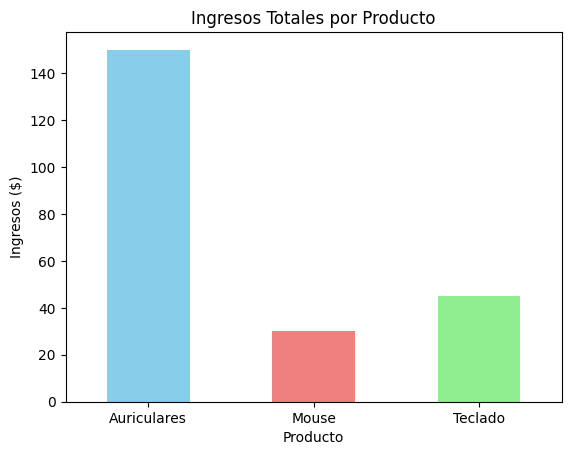

In [4]:
import matplotlib.pyplot as plt

# Creamos el gráfico de barras usando los datos agrupados
ventas_por_producto.plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen'])

# Agregamos título y etiquetas claras para los ejes
plt.title('Ingresos Totales por Producto')
plt.xlabel('Producto')
plt.ylabel('Ingresos ($)')
plt.xticks(rotation=0) # Mantiene los nombres horizontales para leerlos mejor

# Mostramos el gráfico en pantalla
plt.show()


In [5]:
# Calculamos el porcentaje de participación de cada producto
porcentajes = (ventas_por_producto / ingreso_total) * 100

# Redondeamos a 1 decimal para que sea fácil de leer
print(porcentajes.round(1))


Producto
Auriculares    66.7
Mouse          13.3
Teclado        20.0
Name: Total_Venta, dtype: float64


In [6]:
import pandas as pd

# Cada fila es: [Fecha, Producto, Cantidad, Precio]
filas_sucias = [
    ['2026-11-10', 'Auriculares', 2, 25.0],
    ['2026-11-10', ' auriculares ', 1, 25.0],
    ['2026-11-11', 'TECLADO', 1, 45.0],
    ['2026-11-11', 'TECLADO', 1, 45.0],
    ['2026-11-12', 'Mouse', None, 15.0],
    ['2026-11-12', 'teclado', 2, 45.0]
]

# Convertimos la lista en una tabla con nombres de columnas
df = pd.DataFrame(filas_sucias, columns=['Fecha', 'Producto', 'Cantidad', 'Precio'])

print("--- TABLA SUCIA ---")
print(df)


--- TABLA SUCIA ---
        Fecha       Producto  Cantidad  Precio
0  2026-11-10    Auriculares       2.0    25.0
1  2026-11-10   auriculares        1.0    25.0
2  2026-11-11        TECLADO       1.0    45.0
3  2026-11-11        TECLADO       1.0    45.0
4  2026-11-12          Mouse       NaN    15.0
5  2026-11-12        teclado       2.0    45.0


In [7]:
# 1. Quitamos espacios en blanco al inicio y al final (.str.strip())
df['Producto'] = df['Producto'].str.strip()

# 2. Ponemos la primera letra en mayúscula y el resto en minúscula (.str.capitalize())
df['Producto'] = df['Producto'].str.capitalize()

# 3. Eliminamos filas exactamente duplicadas (.drop_duplicates())
df = df.drop_duplicates()

# 4. Rellenamos el dato vacío (NaN) con 1, asumiendo que al menos se vendió 1 unidad (.fillna(1))
df['Cantidad'] = df['Cantidad'].fillna(1)

print("--- TABLA LIMPIA ---")
print(df)


--- TABLA LIMPIA ---
        Fecha     Producto  Cantidad  Precio
0  2026-11-10  Auriculares       2.0    25.0
1  2026-11-10  Auriculares       1.0    25.0
2  2026-11-11      Teclado       1.0    45.0
4  2026-11-12        Mouse       1.0    15.0
5  2026-11-12      Teclado       2.0    45.0


In [8]:
# 1. Creamos la columna de dinero por cada venta
df['Total_Venta'] = df['Cantidad'] * df['Precio']

# 2. Sumamos todo el dinero que ingresó en la tienda
ingreso_real = df['Total_Venta'].sum()
print("Ingreso total real:", ingreso_real)

# 3. Agrupamos por producto para ver cuánto generó cada uno
resumen_limpio = df.groupby('Producto')['Total_Venta'].sum()
print("\nVentas por producto (Tabla Limpia):")
print(resumen_limpio)


Ingreso total real: 225.0

Ventas por producto (Tabla Limpia):
Producto
Auriculares     75.0
Mouse           15.0
Teclado        135.0
Name: Total_Venta, dtype: float64


In [9]:
import pandas as pd
import seaborn as sns

# Cargamos la tabla real directamente desde la memoria interna de Colab
ventas_restaurante = sns.load_dataset('tips')

# Mostramos las primeras 5 filas para conocer la tabla
print("--- PRIMERAS 5 FILAS ---")
print(ventas_restaurante.head())

# Revisamos el tamaño total de la tabla (filas y columnas)
print("\nTamaño de la tabla (filas, columnas):", ventas_restaurante.shape)


--- PRIMERAS 5 FILAS ---
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

Tamaño de la tabla (filas, columnas): (244, 7)


In [10]:
# 1. ¿Cuánto dinero ingresó en total en estas 244 facturas?
venta_total = ventas_restaurante['total_bill'].sum()
print("Venta total del restaurante: $", round(venta_total, 2))

# 2. ¿Qué día de la semana se vende más dinero en total?
ventas_por_dia = ventas_restaurante.groupby('day', observed=False)['total_bill'].sum()
print("\nVentas totales por día:")
print(ventas_por_dia)

# 3. ¿En qué horario se vende más: Almuerzo (Lunch) o Cena (Dinner)?
ventas_por_turno = ventas_restaurante.groupby('time', observed=False)['total_bill'].sum()
print("\nVentas totales por turno:")
print(ventas_por_turno)


Venta total del restaurante: $ 4827.77

Ventas totales por día:
day
Thur    1096.33
Fri      325.88
Sat     1778.40
Sun     1627.16
Name: total_bill, dtype: float64

Ventas totales por turno:
time
Lunch     1167.47
Dinner    3660.30
Name: total_bill, dtype: float64


In [11]:
# 1. Verificamos si existen datos vacíos (NaN) en alguna columna
print("--- AUDITORÍA DE DATOS VACÍOS ---")
print(ventas_restaurante.isnull().sum())

# 2. Calculamos el porcentaje exacto de ventas por día
porcentaje_dia = (ventas_por_dia / venta_total) * 100
print("\n--- PORCENTAJE DE INGRESOS POR DÍA ---")
print(porcentaje_dia.round(1))

# 3. Calculamos el porcentaje exacto de ventas por turno
porcentaje_turno = (ventas_por_turno / venta_total) * 100
print("\n--- PORCENTAJE DE INGRESOS POR TURNO ---")
print(porcentaje_turno.round(1))


--- AUDITORÍA DE DATOS VACÍOS ---
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

--- PORCENTAJE DE INGRESOS POR DÍA ---
day
Thur    22.7
Fri      6.8
Sat     36.8
Sun     33.7
Name: total_bill, dtype: float64

--- PORCENTAJE DE INGRESOS POR TURNO ---
time
Lunch     24.2
Dinner    75.8
Name: total_bill, dtype: float64


--- GASTO PROMEDIO POR TAMAÑO DE MESA ---
size
1     7.24
2    16.45
3    23.28
4    28.61
5    30.07
6    34.83
Name: total_bill, dtype: float64


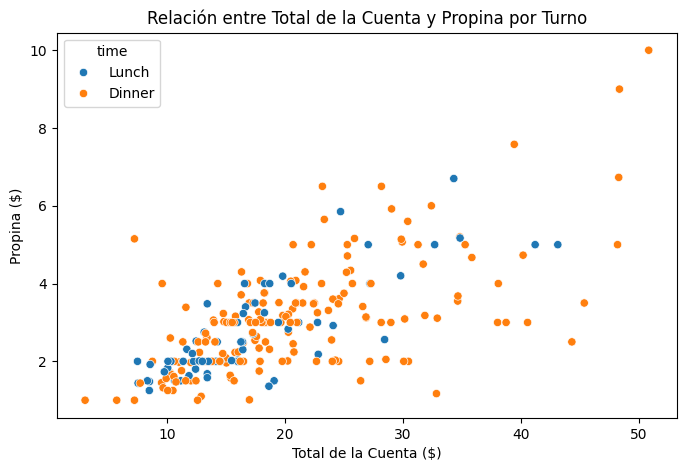

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculamos el gasto PROMEDIO según la cantidad de personas en la mesa
promedio_por_mesa = ventas_restaurante.groupby('size')['total_bill'].mean()
print("--- GASTO PROMEDIO POR TAMAÑO DE MESA ---")
print(promedio_por_mesa.round(2))

# 2. Creamos un gráfico de dispersión para ver la relación entre Factura y Propina
plt.figure(figsize=(8, 5))
sns.scatterplot(data=ventas_restaurante, x='total_bill', y='tip', hue='time')

plt.title('Relación entre Total de la Cuenta y Propina por Turno')
plt.xlabel('Total de la Cuenta ($)')
plt.ylabel('Propina ($)')
plt.show()


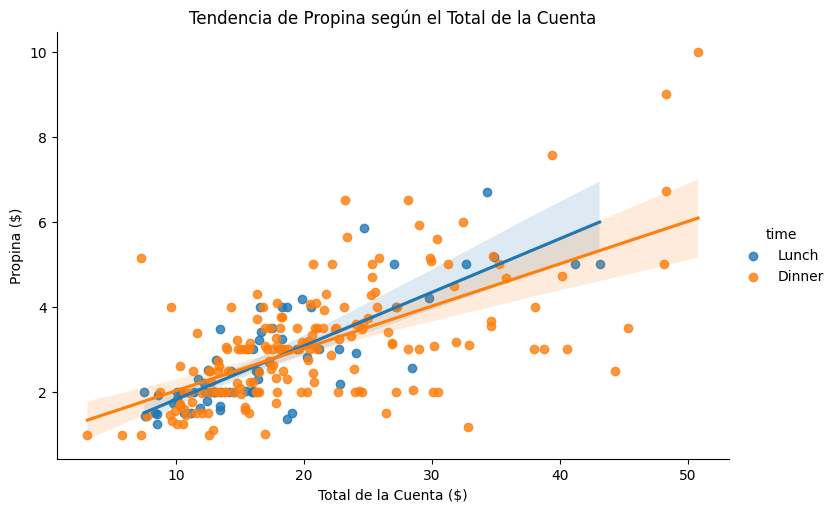

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Creamos el gráfico de puntos con líneas de tendencia para cada turno
sns.lmplot(
    data=ventas_restaurante,
    x='total_bill',
    y='tip',
    hue='time',
    height=5,
    aspect=1.5
)

plt.title('Tendencia de Propina según el Total de la Cuenta')
plt.xlabel('Total de la Cuenta ($)')
plt.ylabel('Propina ($)')
plt.show()
